# 10장 복잡한 생성 과정과 단순한 생성 모델 (실습)

9장과 같은 Hydar 지만 생성 모델을 가능한 한 단순하게 줄인다(캡슐 버전 0.5). 추론하는 숨은 상태는 깊이가 아니라 수온 자체이고(g(μ) = μ), 운동 방정식은 「나는 바라는 수온 μv 로 간다」(f = −μ + μv)뿐이다. 깊이와 수온의 관계(시그모이드)는 모델 어디에도 없다.

1. 단순한 모델로도 17 °C 에 가는가 — 9장과 비교
2. 전방 모델: 정확, 부호 [−1, −1], 위치를 뺀 [0, −1]
3. 유색 잡음 속에서의 진동
4. 일반화 감각: 정확, 후진 차분, 확장
5. 움직이는 물: 가라앉는 해류, 출렁이는 해류
6. 먹이를 찾아 내려갔다 올라오는 움직이는 사전

실패 조건은 고차 감각을 0 으로 채운 확장 방식이다.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import koreanize_matplotlib  # 한글 글꼴과 마이너스 기호 설정
from scipy.linalg import cholesky, toeplitz, inv

SEED = 42
np.random.seed(SEED)
plt.rcParams.update({"figure.figsize": (6.4, 3.2), "figure.dpi": 200,
                     "axes.spines.top": False, "axes.spines.right": False})

dt, T = 0.005, 10.0
t = np.arange(0, T + dt / 2, dt)
N = t.size

def _e(x): return np.exp(5 - x / 5)
def g_gp(x):  return 25 - 16 / (1 + _e(x))
def dg_gp(x): return -16 / 5 * _e(x) / (1 + _e(x))**2

def derivativeD(p): return np.eye(p + 1, k=1)

def temporalC(p, s2):
    q = np.arange(p + 1); r = np.zeros(1 + 2 * p)
    r[2 * q] = np.cumprod(1 - 2 * q) / (2 * s2)**q
    S = np.empty((0, p + 1))
    for i in range(p + 1):
        S = np.vstack([S, r[q + i]]); r = -r
    return S

def makeNoise(C, s2, t):
    C = np.atleast_2d(C)
    w = cholesky(C, lower=True) @ np.random.randn(C.shape[1], np.size(t))
    if s2 <= 1e-5:
        return w
    P = toeplitz(np.exp(-t**2 / (2 * s2)))
    return w @ (P @ np.diag(1 / np.sqrt(np.diag(P.T @ P))))

print(f"시간 점 {N} 개. 깊이 30 의 수온 {g_gp(30):.2f} °C, 깊이 25 의 수온 {g_gp(25):.2f} °C")

시간 점 2001 개. 깊이 30 의 수온 13.30 °C, 깊이 25 의 수온 17.00 °C


## 1. 생성 과정과 캡슐 버전 0.5

생성 과정: x′ = a_gp x + u + v + 출렁임 + w, y = g_gp(x) + z. 처음에는 a_gp = 0, v = 0 이라 Hydar 가 속도를 정한다. 뒤의 실험에서 해류(a_gp = −1, v = 40)와 출렁임을 켠다.

생성 모델(수온 공간): Dμ̃ = −μ̃ + μ̃v, ỹ = μ̃. 그래서 ε̃y = ỹ − μ̃, ∂F/∂μ̃ = (D + I)ᵀ Π̃w ε̃x − Π̃z ε̃y 다.

전방 모델은 Hydar 가 알 수 있는 것만 쓴다.
- sign: [−1, −1, …] 「행동(더 깊이)이 감각을 낮춘다」, 위치 오차까지 쓴다
- sign+: [0, −1, …] 위치 오차는 빼고 변화율 이상만 쓴다
- exact: 생성 과정에서 계산한 [0, g′, …] (비교용, Hydar 는 알 수 없다)

In [2]:
def fwd_model(p, x, method):
    if method == "sign":
        return -np.ones((p + 1, 1))
    f = -np.ones((p + 1, 1)); f[0] = 0
    if method == "exact":
        f[1:] = dg_gp(x)                                    # p = 1 에서 정확한 값 [0, g′]
    return f

def sensor(y_hist, i, p, x, u_tot, method):
    """일반화 감각: exact(생성 과정 식), backward(지난 감각값), extend(고차 = 0)."""
    out = np.zeros((p + 1, 1)); out[0] = y_hist[i]
    if p >= 1:
        if method == "exact":
            out[1] = dg_gp(x) * u_tot
        elif method == "backward" and i >= 1:
            out[1] = (y_hist[i] - y_hist[i - 1]) / dt
    return out


class ai_capsule:
    """수온을 숨은 상태로 두는 가장 단순한 캡슐 (버전 0.5)."""

    def __init__(self, dt, mu_v0, p, s_w, s_z, a_mu, a_u, s2, fwd="sign"):
        self.dt, self.p, self.a_mu, self.a_u, self.fwd = dt, p, a_mu, a_u, fwd
        self.mu = np.zeros((p + 1, 1)); self.mu[0] = mu_v0
        self.u = 0.0
        self.D, self.I = derivativeD(p), np.eye(p + 1)
        self.Pi_w = inv(np.kron(temporalC(p, s2), s_w))
        self.Pi_z = inv(np.kron(temporalC(p, s2), s_z))
        self.e0 = self.I[:, :1]

    def ai_step(self, mu_v, y, x_true, act):
        mu = self.mu
        eps_x = (self.D + self.I) @ mu - self.e0 * mu_v          # Dμ̃ − (−μ̃ + μ̃v)
        eps_y = y - mu                                           # g̃(μ̃) = μ̃
        F = 0.5 * (eps_x.T @ self.Pi_w @ eps_x + eps_y.T @ self.Pi_z @ eps_y).item()
        dF = (self.D + self.I).T @ self.Pi_w @ eps_x - self.Pi_z @ eps_y
        self.mu = mu + self.dt * (self.D @ mu - self.a_mu * dF)
        if act:
            fwd = fwd_model(self.p, x_true, self.fwd)
            self.u += self.dt * -self.a_u * (fwd.T @ self.Pi_z @ eps_y).item()
        return self.u, F, self.mu[0, 0]


def simulation(mu_v, x_init=30.0, s_w=0.1, s_z=0.1, noise="none", a_mu=1.0, a_u=50.0, p=1,
               gen_y="exact", fwd="sign", t_act=2.0, a_gp=0.0, v=0.0, sway=0.0, seed=42):
    mu_v = np.broadcast_to(mu_v, (N,)).astype(float)
    s2 = 1 / 2000 if noise == "smooth" else 1 / 64
    np.random.seed(seed)
    w = makeNoise(s_w, s2, t)[0] if noise == "smooth" else np.zeros(N)
    z = makeNoise(s_z, s2, t)[0] if noise == "smooth" else np.zeros(N)
    cap = ai_capsule(dt, mu_v[0], p, s_w, s_z, a_mu, a_u, s2, fwd)
    out = {k: np.zeros(N) for k in ["x", "y", "mu", "u", "F"]}
    out["x"][0] = x_init; out["y"][0] = g_gp(x_init) + z[0]; out["mu"][0] = mu_v[0]
    u = 0.0
    with np.errstate(all="ignore"):
        for i in range(1, N):
            xd = a_gp * out["x"][i - 1] + u + v + sway * np.sin(t[i] / 0.6) + w[i]
            out["x"][i] = out["x"][i - 1] + dt * xd
            out["y"][i] = g_gp(out["x"][i]) + z[i]
            yt = sensor(out["y"], i, p, out["x"][i], xd, gen_y)
            u, F, m = cap.ai_step(mu_v[i], yt, out["x"][i], t[i] > t_act)
            out["u"][i], out["F"][i], out["mu"][i] = u, F, m
    out["mu_v"] = mu_v
    return out


def arrival(r, target=17.0, tol=0.3, after=0.0):
    """감각 수온이 target ± tol 안에 머물기 시작한 시각."""
    bad = np.where((np.abs(r["y"] - target) >= tol) & (t >= after))[0]
    return t[bad[-1] + 1] if bad.size and bad[-1] + 1 < N else (np.inf if bad.size else after)

def arrival_depth(r, target=25.0, tol=1.0, after=0.0):
    """잡음이 있을 때: 깊이가 target ± tol 안에 머물기 시작한 시각."""
    bad = np.where((np.abs(r["x"] - target) >= tol) & (t >= after))[0]
    return t[bad[-1] + 1] if bad.size and bad[-1] + 1 < N else (np.inf if bad.size else after)

def overshoot(r, target_depth=25.0):
    return max(0.0, target_depth - r["x"].min())

print("ai_capsule v0.5, simulation 준비 완료")

ai_capsule v0.5, simulation 준비 완료


## 2. 단순한 모델로도 17 °C 에 가는가

Hydar 는 깊이 30 (13.3 °C)에서 출발하고 바라는 수온은 17 °C 다. 9장의 첫 실험과 같은 조건(분산 0.1, 잡음 없음, p = 1, 행동은 2 초부터, αu = 50)에 정확한 전방 모델을 쓴다.

In [3]:
r1 = simulation(17.0, fwd="exact", a_u=50)
print(" 시간    깊이     수온    믿음(수온)   행동")
for sec in [1.99, 3, 4, 6, 10]:
    k = int(round(sec / dt))
    print(f"{sec:5.2f}s  {r1['x'][k]:6.2f}   {r1['y'][k]:6.2f}   {r1['mu'][k]:7.2f}    {r1['u'][k]:+6.2f}")
print(f"수온 17±0.3 에 머물기 시작: {arrival(r1):.2f}s,  10초 깊이 {r1['x'][-1]:.3f} cm")

 시간    깊이     수온    믿음(수온)   행동
 1.99s   30.00    13.30     13.79     +0.00
 3.00s   26.74    15.62     15.45     -2.52
 4.00s   25.35    16.72     16.65     -0.60
 6.00s   25.01    16.99     16.99     -0.02
10.00s   25.00    17.00     17.00     +0.00
수온 17±0.3 에 머물기 시작: 3.97s,  10초 깊이 25.000 cm


## 3. 전방 모델

부호 모델 [−1, −1] 을 αu = 1, 50 으로, 위치를 뺀 [0, −1] 을 αu = 50 으로 비교한다. 잡음은 아직 없다.

In [4]:
print("전방 모델        αu    도착     최대 |u|   25 cm 를 넘어선 정도")
for name, fwd, a_u in [("exact [0, g′]", "exact", 50), ("sign [−1, −1]", "sign", 1),
                       ("sign [−1, −1]", "sign", 50), ("sign+ [0, −1]", "sign+", 50)]:
    r = simulation(17.0, fwd=fwd, a_u=a_u)
    print(f"{name:14s}  {a_u:4d}   {arrival(r):5.2f}s   {np.abs(r['u']).max():7.3f}    {overshoot(r):6.3f} cm")

전방 모델        αu    도착     최대 |u|   25 cm 를 넘어선 정도
exact [0, g′]     50    3.97s     4.135     0.000 cm
sign [−1, −1]      1    4.10s     3.068     0.213 cm
sign [−1, −1]     50    5.11s    11.812     0.000 cm
sign+ [0, −1]     50    3.99s     4.327     0.000 cm


## 4. 유색 잡음 속에서

분산 0.1, 매끄러움 1/2000 의 유색 잡음을 넣고 행동은 처음부터 켠다. 부호 모델은 αu = 1, 50, 1000, 위치를 뺀 sign+ 는 αu = 1000 이다. 목표 깊이 25 를 몇 번 가로지르는지(진동)도 센다.

In [5]:
def crossings(r, after=1.0):
    s = np.sign(r["x"][t > after] - 25.0)
    return int(np.sum(s[1:] != s[:-1]))

print("전방 모델   αu    25±1cm 도착   넘어섬      25 cm 가로지름   깊이 변화의 거칠기")
for fwd, a_u in [("sign", 1), ("sign", 50), ("sign", 1000), ("sign+", 1000)]:
    r = simulation(17.0, noise="smooth", fwd=fwd, a_u=a_u, t_act=0.0)
    rough = np.std(np.diff(r["x"][t > 3], 2)) / dt**2
    print(f"{fwd:6s}   {a_u:5d}   {arrival_depth(r):8.2f}s   {overshoot(r):6.3f} cm   {crossings(r):5d}           {rough:8.1f}")

전방 모델   αu    25±1cm 도착   넘어섬      25 cm 가로지름   깊이 변화의 거칠기


sign         1       2.90s    1.218 cm       3               10.5


sign        50       7.07s    3.374 cm      49              191.1


sign      1000       9.97s    4.654 cm     133             1722.9


sign+     1000       1.53s    0.139 cm       7               10.0


## 5. 일반화 감각 — 정확, 후진 차분, 확장

sign+ (αu = 1000), 유색 잡음에서 고차 감각을 만드는 방법만 바꾼다.

In [6]:
print("일반화 감각   25±1cm 도착   마지막 2초 수온    10초 깊이")
r_gen = {}
for gen_y in ["exact", "backward", "extend"]:
    r = simulation(17.0, noise="smooth", fwd="sign+", a_u=1000, t_act=0.0, gen_y=gen_y)
    r_gen[gen_y] = r
    tail = t > 8
    print(f"{gen_y:9s}   {arrival_depth(r):8.2f}s     {r['y'][tail].mean():6.2f}±{r['y'][tail].std():.2f}    {r['x'][-1]:7.2f}")

일반화 감각   25±1cm 도착   마지막 2초 수온    10초 깊이


exact           1.53s      16.94±0.35      24.90


backward        1.74s      16.99±0.28      24.95


extend           infs       8.94±0.33      64.31


## 6. 움직이는 물

해류가 Hydar 를 깊이 40 으로 끌어내린다(a_gp = −1, v = 40). 행동은 5 초부터 켠다. 이어서 출렁임 15 sin(t/0.6) 을 더한다. 후진 차분, sign+ 를 쓴다(원본처럼 αu = 1000, 2500).

In [7]:
for name, kw in [("가라앉는 해류", dict(a_gp=-1.0, v=40.0, a_u=1000)),
                 ("가라앉는 해류 + 출렁임", dict(a_gp=-1.0, v=40.0, sway=15.0, a_u=2500))]:
    r = simulation(17.0, noise="smooth", fwd="sign+", gen_y="backward", t_act=5.0, **kw)
    k5 = int(5 / dt)
    tail = t > 8
    print(f"{name}: 5초 깊이 {r['x'][k5]:.2f} (수온 {r['y'][k5]:.2f}),  25±1cm 도착 {arrival_depth(r, after=5.0):.2f}s,  "
          f"마지막 2초 수온 {r['y'][tail].mean():.2f}±{r['y'][tail].std():.2f},  행동 평균 {r['u'][tail].mean():+.2f}")
print(f"깊이 25 에 머물려면 필요한 행동: u = −(a_gp·25 + v) = {-(-25 + 40):+.1f}")

가라앉는 해류: 5초 깊이 40.02 (수온 9.45),  25±1cm 도착 7.04s,  마지막 2초 수온 16.95±0.28,  행동 평균 -15.31


가라앉는 해류 + 출렁임: 5초 깊이 46.67 (수온 8.90),  25±1cm 도착 infs,  마지막 2초 수온 16.84±0.55,  행동 평균 -21.88
깊이 25 에 머물려면 필요한 행동: u = −(a_gp·25 + v) = -15.0


## 7. 먹이를 찾아 내려갔다 올라오기

해류(a_gp = −1, v = 40)와 유색 잡음 속에서, 사전 수온이 5 초부터 9 초 사이에 가우스 꼴로 5 °C 낮아진다(차가운 물의 먹이). 원본의 설정(σw² = 0.1, σz² = 0.2, αμ = 3, αu = 9500, 후진 차분, sign+)을 쓴다.

In [8]:
from scipy.signal.windows import gaussian
mu_v_food = np.full(N, 17.0)
mu_v_food[1000:1800] = 17 - 5 * gaussian(800, std=120)
r_food = simulation(mu_v_food, s_w=0.1, s_z=0.2, noise="smooth", a_mu=3, a_u=9500,
                    fwd="sign+", gen_y="backward", t_act=2.0, a_gp=-1.0, v=40.0)
k_low = np.argmin(mu_v_food)
k_y = np.argmin(r_food["y"][1000:1900]) + 1000
print(f"사전 최저 {mu_v_food[k_low]:.1f} °C ({t[k_low]:.2f}s),  감각 수온 최저 {r_food['y'][k_y]:.2f} °C ({t[k_y]:.2f}s),  지연 {t[k_y] - t[k_low]:.2f}s")
print(f"가장 깊은 곳 {r_food['x'][1000:1900].max():.2f} cm,  10초 수온 {r_food['y'][-1]:.2f} °C")

사전 최저 12.0 °C (7.00s),  감각 수온 최저 13.31 °C (7.75s),  지연 0.75s
가장 깊은 곳 30.36 cm,  10초 수온 16.81 °C


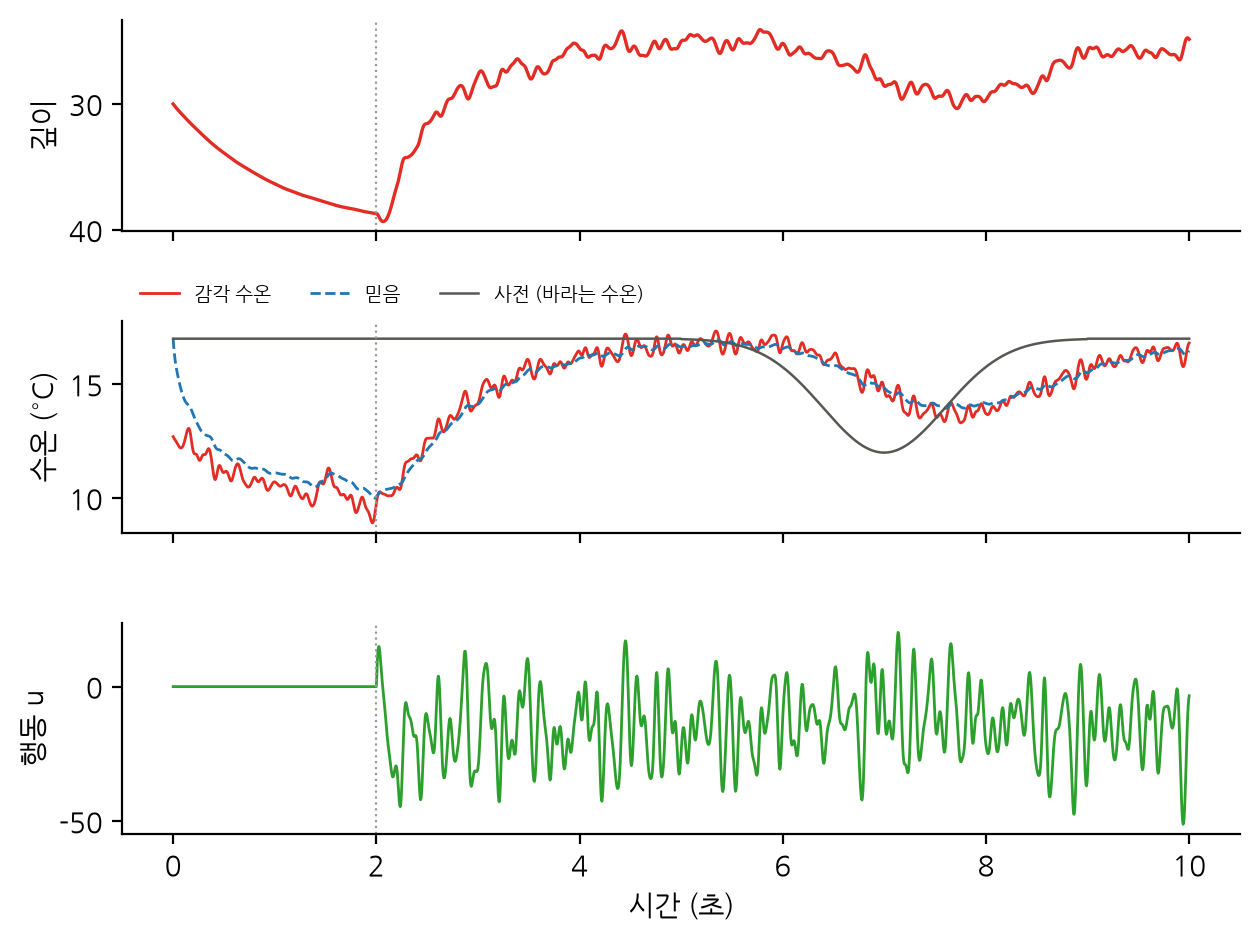

In [9]:
fig, ax = plt.subplots(3, 1, sharex=True, figsize=(6.4, 4.8))
ax[0].plot(t, r_food["x"], color="#E32C24", lw=1.2); ax[0].set_ylabel("깊이")
ax[0].invert_yaxis()
ax[1].plot(t, r_food["y"], color="#E32C24", lw=1.0, label="감각 수온")
ax[1].plot(t, r_food["mu"], color="#1f77b4", lw=1.0, ls="--", label="믿음")
ax[1].plot(t, mu_v_food, color="#575753", lw=0.9, label="사전 (바라는 수온)")
ax[1].set_ylabel("수온 (°C)")
ax[1].legend(frameon=False, fontsize=7, ncol=3, loc="lower left", bbox_to_anchor=(0, 1.0))
ax[2].plot(t, r_food["u"], color="#2ca02c", lw=1.0); ax[2].set_ylabel("행동 u")
ax[2].set_xlabel("시간 (초)")
for a in ax:
    a.axvline(2.0, color="#999999", ls=":", lw=0.8)
fig.tight_layout(); plt.show()

## 결론

- 깊이와 수온의 관계를 전혀 모르는 가장 단순한 생성 모델로도 Hydar 는 17 °C 로 간다. 행동이 조절하는 것은 깊이가 아니라 감각이다.
- 전방 모델은 부호면 충분하다. 다만 위치 오차를 넣느냐에 따라 학습률의 눈금과 진동이 달라진다.
- 잡음 속에서 위치 오차를 넣은 부호 모델에 큰 학습률을 주면 목표를 넘나들고, 위치를 뺀 sign+ 는 진동 없이 간다.
- 고차 감각은 지난 감각값의 차분으로 충분하지만, 0 으로 채우면 행동이 움직이지 못한다.
- 해류나 출렁임이 있어도 Hydar 는 행동을 계속 내어 바라는 수온을 지킨다.